In [33]:
import numpy as np
import pandas as pd
from scipy.optimize import brentq
from scipy.stats import norm

from pricing import call_payoff, put_payoff

In [34]:
# Set the strike price and generate possible prices at expiry.

strike_price = 100
prices_at_expiry = np.linspace(50, 150, 201)

# Calculate both payoffs for every price in the range.

call_payoff_amounts = call_payoff(prices_at_expiry, strike_price)
put_payoff_amounts = put_payoff(prices_at_expiry, strike_price)

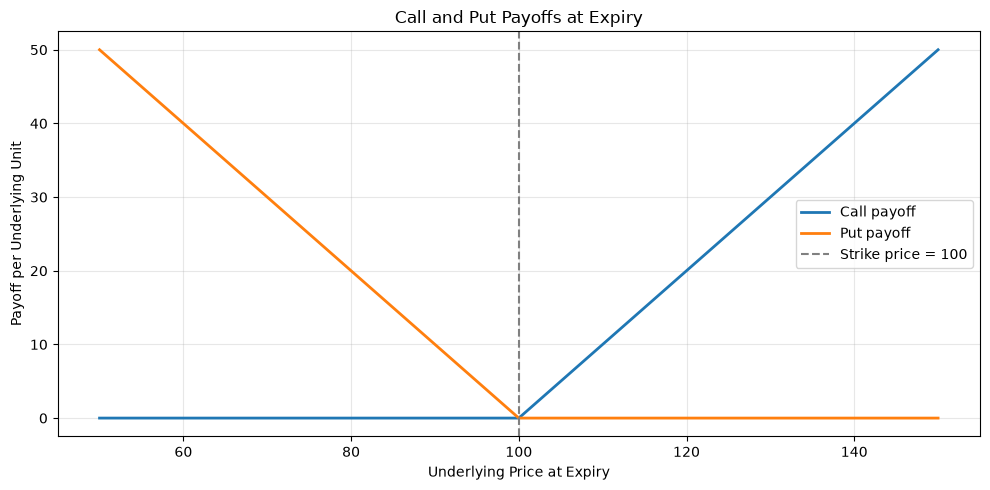

In [35]:
# Create the figure and plotting area.

figure, payoff_axis = plt.subplots(figsize=(10, 5))

# Plot the call and put payoffs.

payoff_axis.plot(
    prices_at_expiry,
    call_payoff_amounts,
    label="Call payoff",
    color="tab:blue",
    linewidth=2,
)

payoff_axis.plot(
    prices_at_expiry,
    put_payoff_amounts,
    label="Put payoff",
    color="tab:orange",
    linewidth=2,
)

# Mark the strike price with a vertical dashed line.

payoff_axis.axvline(
    strike_price,
    color="grey",
    linestyle="--",
    label=f"Strike price = {strike_price}",
)

# Add labels and format the chart.

payoff_axis.set_title("Call and Put Payoffs at Expiry")
payoff_axis.set_xlabel("Underlying Price at Expiry")
payoff_axis.set_ylabel("Payoff per Underlying Unit")
payoff_axis.grid(alpha=0.3)
payoff_axis.legend()

figure.tight_layout()
plt.show()

In [36]:
# Set the Black-Scholes inputs.

current_price = 100
strike_price = 100
risk_free_rate = 0.05
time_to_expiry = 1.0
volatility = 0.20

# Calculate d1 and d2.

d1 = (
    np.log(current_price / strike_price)
    + (risk_free_rate + volatility**2 / 2) * time_to_expiry
) / (volatility * np.sqrt(time_to_expiry))

d2 = d1 - volatility * np.sqrt(time_to_expiry)

print(f"d1: {d1:.4f}")
print(f"d2: {d2:.4f}")

d1: 0.3500
d2: 0.1500


In [37]:
# Calculate the Black-Scholes price of a European call option.



call_option_price = (
    current_price * norm.cdf(d1)
    - strike_price * np.exp(-risk_free_rate * time_to_expiry)
    * norm.cdf(d2)
)

print(f"Call option price: {call_option_price:.4f}")

Call option price: 10.4506


In [38]:
# Calculate the Black-Scholes price of a European put option.

put_option_price = (
    strike_price * np.exp(-risk_free_rate * time_to_expiry)
    * norm.cdf(-d2)
    - current_price * norm.cdf(-d1)
)

print(f"Put option price: {put_option_price:.4f}")

Put option price: 5.5735


In [39]:
# Check put-call parity for a non-dividend-paying stock.

left_hand_side = call_option_price - put_option_price

right_hand_side = (
    current_price
    - strike_price * np.exp(-risk_free_rate * time_to_expiry)
)

print(f"Call price - put price: {left_hand_side:.4f}")
print(f"Current price - discounted strike price: {right_hand_side:.4f}")

Call price - put price: 4.8771
Current price - discounted strike price: 4.8771


In [40]:
# Calculate the Black-Scholes price of a European call option.

def black_scholes_call_price(
    current_price,
    strike_price,
    risk_free_rate,
    time_to_expiry,
    volatility,
):
    d1 = (
        np.log(current_price / strike_price)
        + (risk_free_rate + volatility**2 / 2) * time_to_expiry
    ) / (volatility * np.sqrt(time_to_expiry))

    d2 = d1 - volatility * np.sqrt(time_to_expiry)

    call_option_price = (
        current_price * norm.cdf(d1)
        - strike_price * np.exp(-risk_free_rate * time_to_expiry)
        * norm.cdf(d2)
    )

    return call_option_price

In [41]:
# Price the call option using the reusable function.

call_option_price = black_scholes_call_price(
    current_price=100,
    strike_price=100,
    risk_free_rate=0.05,
    time_to_expiry=1.0,
    volatility=0.20,
)

print(f"Call option price: {call_option_price:.4f}")

Call option price: 10.4506


In [42]:
def black_scholes_put_price(
    current_price,
    strike_price,
    risk_free_rate,
    time_to_expiry,
    volatility,
):
    # Calculate d1 and d2.

    d1 = (
        np.log(current_price / strike_price)
        + (risk_free_rate + volatility**2 / 2) * time_to_expiry
    ) / (volatility * np.sqrt(time_to_expiry))

    d2 = d1 - volatility * np.sqrt(time_to_expiry)

    # Calculate the European put price.

    put_option_price = (
        strike_price * np.exp(-risk_free_rate * time_to_expiry)
        * norm.cdf(-d2)
        - current_price * norm.cdf(-d1)
    )

    return put_option_price

In [43]:
# Price the put option using the reusable function.

put_option_price = black_scholes_put_price(
    current_price=100,
    strike_price=100,
    risk_free_rate=0.05,
    time_to_expiry=1.0,
    volatility=0.20,
)

print(f"Put option price: {put_option_price:.4f}")

Put option price: 5.5735


In [44]:
# Set the option inputs.

current_price = 100
strike_price = 100
risk_free_rate = 0.05
time_to_expiry = 1.0
volatility = 0.20
num_steps = 3

In [45]:
# Calculate the length of each time step.

time_step = time_to_expiry / num_steps

# Calculate the up and down movement factors.

up_factor = np.exp(volatility * np.sqrt(time_step))
down_factor = 1 / up_factor

# Calculate the risk-neutral probability of an up move.

up_probability = (
    np.exp(risk_free_rate * time_step) - down_factor
) / (up_factor - down_factor)

# Calculate the discount factor for one time step.

discount_factor = np.exp(-risk_free_rate * time_step)

print(f"Up factor: {up_factor:.4f}")
print(f"Down factor: {down_factor:.4f}")
print(f"Risk-neutral up probability: {up_probability:.4f}")

Up factor: 1.1224
Down factor: 0.8909
Risk-neutral up probability: 0.5438


In [46]:
# Create the matrix, including a row for today.

stock_prices = np.zeros((num_steps + 1, num_steps + 1))

# Calculate the stock price at each node.

for step in range(num_steps + 1):
    for up_moves in range(step + 1):
        down_moves = step - up_moves

        stock_prices[step, up_moves] = (
            current_price
            * up_factor**up_moves
            * down_factor**down_moves
        )

print(np.round(stock_prices, 4))

[[100.       0.       0.       0.    ]
 [ 89.0947 112.2401   0.       0.    ]
 [ 79.3787 100.     125.9784   0.    ]
 [ 70.7222  89.0947 112.2401 141.3982]]


In [47]:
# Create a matrix to hold call option values.

call_prices = np.zeros_like(stock_prices)

# Extract the stock prices at expiry.

prices_at_expiry = stock_prices[-1, :]

# Calculate the call payoffs at expiry.

call_prices[-1, :] = np.maximum(
    prices_at_expiry - strike_price,
    0.0,
)

print(np.round(call_prices[-1, :], 4))

[ 0.      0.     12.2401 41.3982]


In [48]:
# Work backwards from the step before expiry to today.

for step in range(num_steps - 1, -1, -1):
    for up_moves in range(step + 1):
        call_prices[step, up_moves] = discount_factor * (
            up_probability * call_prices[step + 1, up_moves + 1]
            + (1 - up_probability) * call_prices[step + 1, up_moves]
        )

# The first node contains the option price today.

print(f"Three-step binomial call price: {call_prices[0, 0]:.4f}")

Three-step binomial call price: 11.0439


In [49]:
def binomial_option_price(
    current_price,
    strike_price,
    risk_free_rate,
    time_to_expiry,
    volatility,
    num_steps,
    option_type="call",
):
    # Check the basic inputs.

    if not isinstance(num_steps, int) or num_steps < 1:
        raise ValueError("Number of steps must be a positive integer.")

    if option_type not in ("call", "put"):
        raise ValueError("Option type must be 'call' or 'put'.")

    if min(current_price, strike_price, time_to_expiry, volatility) <= 0:
        raise ValueError("Prices, time and volatility must be positive.")

    # Calculate the movement and discount factors for each step.

    time_step = time_to_expiry / num_steps
    up_factor = np.exp(volatility * np.sqrt(time_step))
    down_factor = 1 / up_factor
    discount_factor = np.exp(-risk_free_rate * time_step)

    up_probability = (
        np.exp(risk_free_rate * time_step) - down_factor
    ) / (up_factor - down_factor)

    if not 0 < up_probability < 1:
        raise ValueError("Invalid tree probability. Increase num_steps.")

    # Create the stock and option price matrices.

    stock_prices = np.zeros((num_steps + 1, num_steps + 1))
    option_prices = np.zeros_like(stock_prices)

    # Build the stock price tree.

    for step in range(num_steps + 1):
        for up_moves in range(step + 1):
            down_moves = step - up_moves

            stock_prices[step, up_moves] = (
                current_price
                * up_factor**up_moves
                * down_factor**down_moves
            )

    # Calculate the option payoffs at expiry.

    prices_at_expiry = stock_prices[-1, :]

    if option_type == "call":
        option_prices[-1, :] = np.maximum(
            prices_at_expiry - strike_price,
            0.0,
        )
    else:
        option_prices[-1, :] = np.maximum(
            strike_price - prices_at_expiry,
            0.0,
        )

    # Work backwards through the tree.

    for step in range(num_steps - 1, -1, -1):
        for up_moves in range(step + 1):
            option_prices[step, up_moves] = discount_factor * (
                up_probability * option_prices[step + 1, up_moves + 1]
                + (1 - up_probability) * option_prices[step + 1, up_moves]
            )

    return float(option_prices[0, 0])

In [50]:
# Calculate the Black-Scholes benchmark prices.

black_scholes_call = black_scholes_call_price(
    current_price,
    strike_price,
    risk_free_rate,
    time_to_expiry,
    volatility,
)

black_scholes_put = black_scholes_put_price(
    current_price,
    strike_price,
    risk_free_rate,
    time_to_expiry,
    volatility,
)

# Calculate the binomial prices using 100 steps.

binomial_call_price = binomial_option_price(
    current_price,
    strike_price,
    risk_free_rate,
    time_to_expiry,
    volatility,
    num_steps=100,
    option_type="call",
)

binomial_put_price = binomial_option_price(
    current_price,
    strike_price,
    risk_free_rate,
    time_to_expiry,
    volatility,
    num_steps=100,
    option_type="put",
)

# Display the comparison.

price_comparison = pd.DataFrame(
    {
        "Option": ["Call", "Put"],
        "Black-Scholes": [black_scholes_call, black_scholes_put],
        "Binomial": [binomial_call_price, binomial_put_price],
    }
)

price_comparison.round(4)

,Option,Black-Scholes,Binomial
0,Call,10.4506,10.4306
1,Put,5.5735,5.5536


In [52]:
# Compare binomial prices across different tree sizes.

convergence_results = []

for step_count in [10, 25, 50, 100, 250, 500, 1000, 2500, 5000]:
    tree_price = binomial_option_price(
        current_price,
        strike_price,
        risk_free_rate,
        time_to_expiry,
        volatility,
        num_steps=step_count,
        option_type="call",
    )

    convergence_results.append(
        {
            "Steps": step_count,
            "Binomial price": tree_price,
            "Black-Scholes price": black_scholes_call,
            "Pricing difference": tree_price - black_scholes_call,
        }
    )

convergence_table = pd.DataFrame(convergence_results)

convergence_table.round(4)

,Steps,Binomial price,Black-Scholes price,Pricing difference
0,10,10.2534,10.4506,-0.1972
1,25,10.5210,10.4506,0.0704
2,50,10.4107,10.4506,-0.0399
3,100,10.4306,10.4506,-0.0200
4,250,10.4426,10.4506,-0.0080
5,500,10.4466,10.4506,-0.0040
6,1000,10.4486,10.4506,-0.0020
7,2500,10.4498,10.4506,-0.0008
8,5000,10.4502,10.4506,-0.0004


In [53]:
# Calculate the difference between both sides of put-call parity.

parity_difference = (
    binomial_call_price
    - binomial_put_price
    - current_price
    + strike_price * np.exp(-risk_free_rate * time_to_expiry)
)

# Allow a small tolerance for floating-point calculations.

parity_passed = np.isclose(
    parity_difference,
    0.0,
    atol=1e-10,
    rtol=0.0,
)

print(f"Put-call parity passed: {parity_passed}")

Put-call parity passed: True


In [54]:
def call_price_error(
    volatility,
    current_price,
    strike_price,
    risk_free_rate,
    time_to_expiry,
    market_option_price,
):
    # Calculate the call price using the trial volatility.

    model_price = black_scholes_call_price(
        current_price,
        strike_price,
        risk_free_rate,
        time_to_expiry,
        volatility,
    )

    # Return the difference between model and market prices.

    return model_price - market_option_price

In [55]:
# Use an illustrative option quote, not a live market price.

market_option_price = 10.4506

# Check the price bounds for a positive-volatility European call.

minimum_call_price = max(
    0.0,
    current_price
    - strike_price * np.exp(-risk_free_rate * time_to_expiry),
)

if not minimum_call_price < market_option_price < current_price:
    raise ValueError("Quote must lie inside the call price bounds.")

# Collect the inputs that remain fixed during the search.

pricing_inputs = (
    current_price,
    strike_price,
    risk_free_rate,
    time_to_expiry,
    market_option_price,
)

# Search between 0.01% and 300% annual volatility.

implied_volatility = brentq(
    call_price_error,
    a=0.0001,
    b=3.0,
    args=pricing_inputs,
)

print(f"Implied volatility: {implied_volatility:.2%}")

Implied volatility: 20.00%


In [56]:
# Reprice the option using the estimated implied volatility.

repriced_call = black_scholes_call_price(
    current_price,
    strike_price,
    risk_free_rate,
    time_to_expiry,
    implied_volatility,
)

repricing_error = repriced_call - market_option_price

print(f"Example market price: {market_option_price:.4f}")
print(f"Repriced call: {repriced_call:.4f}")
print(f"Absolute repricing error: {abs(repricing_error):.10f}")

Example market price: 10.4506
Repriced call: 10.4506
Absolute repricing error: 0.0000000000


In [62]:
# Import the libraries used in this section.

import numpy as np
import pandas as pd
from scipy.stats import norm

# Set the option inputs.

current_price = 100
strike_price = 100
risk_free_rate = 0.05
time_to_expiry = 1.0
volatility = 0.20

# Calculate the common Black-Scholes terms.

d1 = (
    np.log(current_price / strike_price)
    + (risk_free_rate + volatility**2 / 2) * time_to_expiry
) / (volatility * np.sqrt(time_to_expiry))

d2 = d1 - volatility * np.sqrt(time_to_expiry)

normal_density = norm.pdf(d1)

discounted_strike_price = strike_price * np.exp(
    -risk_free_rate * time_to_expiry
)

In [63]:
# Calculate call and put delta.

call_delta = norm.cdf(d1)
put_delta = norm.cdf(d1) - 1

# Gamma is the same for matching calls and puts.

gamma = normal_density / (
    current_price * volatility * np.sqrt(time_to_expiry)
)

# Vega is also the same for matching calls and puts.

vega = current_price * normal_density * np.sqrt(time_to_expiry)

In [64]:
# Calculate the common component of call and put theta.

time_decay_component = -(
    current_price * normal_density * volatility
) / (2 * np.sqrt(time_to_expiry))

# Calculate annual theta.

call_theta = (
    time_decay_component
    - risk_free_rate * discounted_strike_price * norm.cdf(d2)
)

put_theta = (
    time_decay_component
    + risk_free_rate * discounted_strike_price * norm.cdf(-d2)
)

# Calculate rho using interest rates expressed as decimals.

call_rho = time_to_expiry * discounted_strike_price * norm.cdf(d2)

put_rho = -time_to_expiry * discounted_strike_price * norm.cdf(-d2)

In [65]:
# Display the Greeks using clearly labelled units.

greeks_table = pd.DataFrame(
    {
        "Greek": [
            "Delta",
            "Gamma",
            "Vega per 1 pp",
            "Theta per calendar day",
            "Rho per 1 pp",
        ],
        "Call": [
            call_delta,
            gamma,
            vega * 0.01,
            call_theta / 365,
            call_rho * 0.01,
        ],
        "Put": [
            put_delta,
            gamma,
            vega * 0.01,
            put_theta / 365,
            put_rho * 0.01,
        ],
    }
)

greeks_table.round(4)

,Greek,Call,Put
0,Delta,0.6368,-0.3632
1,Gamma,0.0188,0.0188
2,Vega per 1 pp,0.3752,0.3752
3,Theta per calendar day,-0.0176,-0.0045
4,Rho per 1 pp,0.5323,-0.4189


In [66]:
def black_scholes_greeks(
    current_price,
    strike_price,
    risk_free_rate,
    time_to_expiry,
    volatility,
    option_type="call",
):
    # Check the inputs supported by this version.

    if option_type not in ("call", "put"):
        raise ValueError("Option type must be 'call' or 'put'.")

    if min(current_price, strike_price, time_to_expiry, volatility) <= 0:
        raise ValueError("Prices, time and volatility must be positive.")

    # Calculate the common Black-Scholes terms.

    d1 = (
        np.log(current_price / strike_price)
        + (risk_free_rate + volatility**2 / 2) * time_to_expiry
    ) / (volatility * np.sqrt(time_to_expiry))

    d2 = d1 - volatility * np.sqrt(time_to_expiry)

    normal_density = norm.pdf(d1)

    discounted_strike_price = strike_price * np.exp(
        -risk_free_rate * time_to_expiry
    )

    # Gamma and vega are the same for matching calls and puts.

    gamma = normal_density / (
        current_price * volatility * np.sqrt(time_to_expiry)
    )

    vega = current_price * normal_density * np.sqrt(time_to_expiry)

    time_decay_component = -(
        current_price * normal_density * volatility
    ) / (2 * np.sqrt(time_to_expiry))

    # Calculate the option-specific Greeks.

    if option_type == "call":
        delta = norm.cdf(d1)

        theta = (
            time_decay_component
            - risk_free_rate * discounted_strike_price * norm.cdf(d2)
        )

        rho = time_to_expiry * discounted_strike_price * norm.cdf(d2)

    else:
        delta = norm.cdf(d1) - 1

        theta = (
            time_decay_component
            + risk_free_rate * discounted_strike_price * norm.cdf(-d2)
        )

        rho = -time_to_expiry * discounted_strike_price * norm.cdf(-d2)

    # Return raw derivatives; theta is per year of elapsed time.

    return {
        "delta": delta,
        "gamma": gamma,
        "vega": vega,
        "theta": theta,
        "rho": rho,
    }

In [67]:
# Store the inputs used by the pricing functions.

market_inputs = {
    "current_price": current_price,
    "strike_price": strike_price,
    "risk_free_rate": risk_free_rate,
    "time_to_expiry": time_to_expiry,
    "volatility": volatility,
}

# Associate each option type with its pricing function.

pricing_functions = {
    "call": black_scholes_call_price,
    "put": black_scholes_put_price,
}

# Associate each input with its Greek and numerical bump size.

bump_settings = {
    "current_price": ("delta", 0.01),
    "volatility": ("vega", 0.0001),
    "time_to_expiry": ("theta", 0.0001),
    "risk_free_rate": ("rho", 0.0001),
}

In [68]:
# Compare analytical Greeks with finite-difference estimates.

validation_rows = []

for option_type, pricing_function in pricing_functions.items():
    analytical_greeks = black_scholes_greeks(
        **market_inputs,
        option_type=option_type,
    )

    base_price = pricing_function(**market_inputs)

    for input_name, (greek_name, bump_size) in bump_settings.items():
        # Change one input while holding the others fixed.

        higher_inputs = market_inputs.copy()
        lower_inputs = market_inputs.copy()

        higher_inputs[input_name] += bump_size
        lower_inputs[input_name] -= bump_size

        higher_price = pricing_function(**higher_inputs)
        lower_price = pricing_function(**lower_inputs)

        numerical_greek = (higher_price - lower_price) / (2 * bump_size)

        # Theta measures elapsed time, not increasing time to expiry.

        if greek_name == "theta":
            numerical_greek = -numerical_greek

        validation_rows.append(
            {
                "Option": option_type,
                "Greek": greek_name,
                "Analytical": analytical_greeks[greek_name],
                "Numerical": numerical_greek,
            }
        )

        # Reuse the stock-price bumps to estimate gamma.

        if greek_name == "delta":
            numerical_gamma = (
                higher_price - 2 * base_price + lower_price
            ) / bump_size**2

            validation_rows.append(
                {
                    "Option": option_type,
                    "Greek": "gamma",
                    "Analytical": analytical_greeks["gamma"],
                    "Numerical": numerical_gamma,
                }
            )

# Check agreement within numerical tolerances.

validation_table = pd.DataFrame(validation_rows)

validation_table["Passed"] = np.isclose(
    validation_table["Analytical"],
    validation_table["Numerical"],
    rtol=1e-4,
    atol=1e-6,
)

assert validation_table["Passed"].all(), "A Greek check failed."

validation_table.round(6)

,Option,Greek,Analytical,Numerical,Passed
0,call,delta,0.636831,0.636831,True
1,call,gamma,0.018762,0.018762,True
2,call,vega,37.524035,37.524034,True
3,call,theta,-6.414028,-6.414028,True
4,call,rho,53.232482,53.232481,True
5,put,delta,-0.363169,-0.363169,True
6,put,gamma,0.018762,0.018762,True
7,put,vega,37.524035,37.524034,True
8,put,theta,-1.657880,-1.657880,True
9,put,rho,-41.890461,-41.890462,True


In [69]:
# Define hypothetical changes from the current market inputs.

scenario_inputs = pd.DataFrame(
    [
        ("Stock down 5%", -0.05, 0.00, 0.0000, 0),
        ("Stock up 5%", 0.05, 0.00, 0.0000, 0),
        ("Volatility up 2 pp", 0.00, 0.02, 0.0000, 0),
        ("Rates up 25 bp", 0.00, 0.00, 0.0025, 0),
        ("One calendar day", 0.00, 0.00, 0.0000, 1),
        ("Combined stress", -0.05, 0.02, 0.0025, 1),
    ],
    columns=[
        "name",
        "price_return",
        "volatility_change",
        "rate_change",
        "days_passed",
    ],
)

scenario_inputs

,name,price_return,volatility_change,rate_change,days_passed
0,Stock down 5%,-0.05,0.00,0.0000,0
1,Stock up 5%,0.05,0.00,0.0000,0
2,Volatility up 2 pp,0.00,0.02,0.0000,0
3,Rates up 25 bp,0.00,0.00,0.0025,0
4,One calendar day,0.00,0.00,0.0000,1
5,Combined stress,-0.05,0.02,0.0025,1


In [70]:
# Calculate the starting call price and Greeks.

base_call_price = black_scholes_call_price(**market_inputs)

call_greeks = black_scholes_greeks(
    **market_inputs,
    option_type="call",
)

scenario_rows = []

# Calculate the price change under each scenario.

for scenario in scenario_inputs.itertuples(index=False):
    price_change = current_price * scenario.price_return
    elapsed_years = scenario.days_passed / 365

    scenario_call_price = black_scholes_call_price(
        current_price=current_price + price_change,
        strike_price=strike_price,
        risk_free_rate=risk_free_rate + scenario.rate_change,
        time_to_expiry=time_to_expiry - elapsed_years,
        volatility=volatility + scenario.volatility_change,
    )

    # Calculate P&L using full repricing.

    full_repricing_pnl = scenario_call_price - base_call_price

    # Estimate P&L using the initial Greeks.

    greek_pnl = (
        call_greeks["delta"] * price_change
        + 0.5 * call_greeks["gamma"] * price_change**2
        + call_greeks["vega"] * scenario.volatility_change
        + call_greeks["rho"] * scenario.rate_change
        + call_greeks["theta"] * elapsed_years
    )

    scenario_rows.append(
        {
            "Scenario": scenario.name,
            "Full repricing P&L": full_repricing_pnl,
            "Greek estimate P&L": greek_pnl,
            "Approximation error": greek_pnl - full_repricing_pnl,
        }
    )

scenario_results = pd.DataFrame(scenario_rows)

scenario_results.round(4)

,Scenario,Full repricing P&L,Greek estimate P&L,Approximation error
0,Stock down 5%,-2.9397,-2.9496,-0.0099
1,Stock up 5%,3.4073,3.4187,0.0114
2,Volatility up 2 pp,0.7522,0.7505,-0.0017
3,Rates up 25 bp,0.1335,0.1331,-0.0004
4,One calendar day,-0.0176,-0.0176,0.0000
5,Combined stress,-2.0947,-2.0836,0.0111


In [71]:
# Define the example position.

number_of_contracts = 10
contract_multiplier = 100

position_scale = number_of_contracts * contract_multiplier

# Scale the per-unit results to the full position.

position_results = scenario_results.copy()

for column in [
    "Full repricing P&L",
    "Greek estimate P&L",
    "Approximation error",
]:
    position_results[column] *= position_scale

position_results.round(2)

,Scenario,Full repricing P&L,Greek estimate P&L,Approximation error
0,Stock down 5%,-2939.71,-2949.63,-9.92
1,Stock up 5%,3407.32,3418.68,11.36
2,Volatility up 2 pp,752.23,750.48,-1.75
3,Rates up 25 bp,133.50,133.08,-0.42
4,One calendar day,-17.58,-17.57,0.01
5,Combined stress,-2094.69,-2083.64,11.05


In [72]:
# Import the libraries used in this section.

import numpy as np
import pandas as pd
from scipy.stats import norm

# Set the option inputs.

current_price = 100
strike_price = 100
risk_free_rate = 0.05
time_to_expiry = 1.0
volatility = 0.20

# Set the simulation size and random seed.

num_simulations = 100_000
random_seed = 42

In [73]:
# Create a local random number generator.

random_generator = np.random.default_rng(random_seed)

# Generate one standard normal shock for each simulation.

random_shocks = random_generator.standard_normal(num_simulations)

print(f"Number of simulated shocks: {len(random_shocks):,}")

Number of simulated shocks: 100,000


In [74]:
# Simulate prices at expiry under the risk-neutral model.

prices_at_expiry = current_price * np.exp(
    (risk_free_rate - 0.5 * volatility**2) * time_to_expiry
    + volatility * np.sqrt(time_to_expiry) * random_shocks
)

# Display the first five simulated prices.

print(np.round(prices_at_expiry[:5], 4))

[109.5207  83.6945 119.7325 124.3728  69.7532]


In [75]:
# Calculate the call and put payoffs in each simulation.

call_payoffs = np.maximum(prices_at_expiry - strike_price, 0.0)
put_payoffs = np.maximum(strike_price - prices_at_expiry, 0.0)

# Discount the payoffs back to today.

discount_factor = np.exp(-risk_free_rate * time_to_expiry)

discounted_call_payoffs = discount_factor * call_payoffs
discounted_put_payoffs = discount_factor * put_payoffs

# Estimate each option price using the average discounted payoff.

monte_carlo_call_price = np.mean(discounted_call_payoffs)
monte_carlo_put_price = np.mean(discounted_put_payoffs)

print(f"Monte Carlo call price: {monte_carlo_call_price:.4f}")
print(f"Monte Carlo put price: {monte_carlo_put_price:.4f}")

Monte Carlo call price: 10.4205
Monte Carlo put price: 5.6122


In [76]:
# Calculate the standard errors using sample standard deviations.

call_standard_error = np.std(discounted_call_payoffs, ddof=1) / np.sqrt(
    num_simulations
)

put_standard_error = np.std(discounted_put_payoffs, ddof=1) / np.sqrt(
    num_simulations
)

# Calculate the margins for approximate 95% confidence intervals.

confidence_multiplier = norm.ppf(0.975)

call_confidence_margin = confidence_multiplier * call_standard_error
put_confidence_margin = confidence_multiplier * put_standard_error

# Display the estimates and their sampling uncertainty.

monte_carlo_summary = pd.DataFrame(
    {
        "Option": ["Call", "Put"],
        "Estimate": [monte_carlo_call_price, monte_carlo_put_price],
        "Standard error": [call_standard_error, put_standard_error],
        "95% CI lower": [
            monte_carlo_call_price - call_confidence_margin,
            monte_carlo_put_price - put_confidence_margin,
        ],
        "95% CI upper": [
            monte_carlo_call_price + call_confidence_margin,
            monte_carlo_put_price + put_confidence_margin,
        ],
    }
)

monte_carlo_summary.round(4)

,Option,Estimate,Standard error,95% CI lower,95% CI upper
0,Call,10.4205,0.0468,10.3289,10.5122
1,Put,5.6122,0.0275,5.5583,5.6661


In [77]:
def monte_carlo_option_price(
    current_price,
    strike_price,
    risk_free_rate,
    time_to_expiry,
    volatility,
    num_simulations=100_000,
    option_type="call",
    random_seed=42,
):
    # Check the inputs supported by this version.

    if not isinstance(num_simulations, int) or num_simulations < 2:
        raise ValueError("Number of simulations must be an integer above 1.")

    if option_type not in ("call", "put"):
        raise ValueError("Option type must be 'call' or 'put'.")

    numerical_inputs = [
        current_price,
        strike_price,
        risk_free_rate,
        time_to_expiry,
        volatility,
    ]

    if not np.all(np.isfinite(numerical_inputs)):
        raise ValueError("All numerical inputs must be finite.")

    if min(current_price, strike_price, time_to_expiry, volatility) <= 0:
        raise ValueError("Prices, time and volatility must be positive.")

    # Simulate terminal prices under the risk-neutral model.

    random_generator = np.random.default_rng(random_seed)
    random_shocks = random_generator.standard_normal(num_simulations)

    prices_at_expiry = current_price * np.exp(
        (risk_free_rate - 0.5 * volatility**2) * time_to_expiry
        + volatility * np.sqrt(time_to_expiry) * random_shocks
    )

    # Calculate and discount the option payoffs.

    if option_type == "call":
        option_payoffs = np.maximum(prices_at_expiry - strike_price, 0.0)
    else:
        option_payoffs = np.maximum(strike_price - prices_at_expiry, 0.0)

    discounted_payoffs = (
        np.exp(-risk_free_rate * time_to_expiry) * option_payoffs
    )

    # Estimate the option price and its standard error.

    option_price = np.mean(discounted_payoffs)

    standard_error = np.std(discounted_payoffs, ddof=1) / np.sqrt(
        num_simulations
    )

    confidence_margin = norm.ppf(0.975) * standard_error

    return {
        "option_price": float(option_price),
        "standard_error": float(standard_error),
        "ci_lower": float(option_price - confidence_margin),
        "ci_upper": float(option_price + confidence_margin),
    }

In [78]:
# Store the shared pricing inputs.

simulation_inputs = {
    "current_price": current_price,
    "strike_price": strike_price,
    "risk_free_rate": risk_free_rate,
    "time_to_expiry": time_to_expiry,
    "volatility": volatility,
}

pricing_functions = {
    "call": black_scholes_call_price,
    "put": black_scholes_put_price,
}

comparison_rows = []

# Price each option using all three methods.

for option_type, pricing_function in pricing_functions.items():
    benchmark_price = pricing_function(**simulation_inputs)

    tree_price = binomial_option_price(
        **simulation_inputs,
        num_steps=500,
        option_type=option_type,
    )

    simulation_result = monte_carlo_option_price(
        **simulation_inputs,
        num_simulations=100_000,
        option_type=option_type,
        random_seed=42,
    )

    comparison_rows.append(
        {
            "Option": option_type,
            "Black-Scholes": benchmark_price,
            "Binomial": tree_price,
            "Monte Carlo": simulation_result["option_price"],
            "MC error": (
                simulation_result["option_price"] - benchmark_price
            ),
            "BS inside MC interval": (
                simulation_result["ci_lower"]
                <= benchmark_price
                <= simulation_result["ci_upper"]
            ),
        }
    )

model_comparison = pd.DataFrame(comparison_rows)

model_comparison.round(4)

,Option,Black-Scholes,Binomial,Monte Carlo,MC error,BS inside MC interval
0,call,10.4506,10.4466,10.4205,-0.0300,True
1,put,5.5735,5.5695,5.6122,0.0387,True


In [79]:
# Calculate the analytical call-price benchmark.

benchmark_price = black_scholes_call_price(**simulation_inputs)

convergence_rows = []

# Repeat the calculation with increasing simulation sizes.

for simulation_count in [
    5_000,
    10_000,
    50_000,
    100_000,
    500_000,
    1_000_000,
]:
    result = monte_carlo_option_price(
        **simulation_inputs,
        num_simulations=simulation_count,
        option_type="call",
        random_seed=42,
    )

    convergence_rows.append(
        {
            "Simulations": simulation_count,
            "Estimate": result["option_price"],
            "Black-Scholes": benchmark_price,
            "Standard error": result["standard_error"],
            "95% CI lower": result["ci_lower"],
            "95% CI upper": result["ci_upper"],
        }
    )

monte_carlo_convergence = pd.DataFrame(convergence_rows)

monte_carlo_convergence.round(4)

,Simulations,Estimate,Black-Scholes,Standard error,95% CI lower,95% CI upper
0,5000,10.1689,10.4506,0.2059,9.7654,10.5724
1,10000,10.3452,10.4506,0.1477,10.0558,10.6346
2,50000,10.4577,10.4506,0.0661,10.3281,10.5873
3,100000,10.4205,10.4506,0.0468,10.3289,10.5122
4,500000,10.4500,10.4506,0.0209,10.4092,10.4909
5,1000000,10.4532,10.4506,0.0147,10.4243,10.4821


In [80]:
# Repeat the same pricing experiment using different random seeds.

num_repetitions = 30
repetition_rows = []

for seed in range(num_repetitions):
    result = monte_carlo_option_price(
        **simulation_inputs,
        num_simulations=50_000,
        option_type="call",
        random_seed=seed,
    )

    repetition_rows.append(
        {
            "Seed": seed,
            "Estimate": result["option_price"],
            "Standard error": result["standard_error"],
            "Contains benchmark": (
                result["ci_lower"]
                <= benchmark_price
                <= result["ci_upper"]
            ),
        }
    )

repetition_table = pd.DataFrame(repetition_rows)

# Compare observed variation with the reported standard errors.

covered_runs = repetition_table["Contains benchmark"].sum()

observed_spread = repetition_table["Estimate"].std(ddof=1)

reported_standard_error = repetition_table["Standard error"].mean()

print(
    f"Intervals containing Black-Scholes: "
    f"{covered_runs}/{num_repetitions}"
)
print(f"SD across estimates: {observed_spread:.4f}")
print(f"Mean reported standard error: {reported_standard_error:.4f}")

Intervals containing Black-Scholes: 29/30
SD across estimates: 0.0645
Mean reported standard error: 0.0657
